# Meta-Monomorphizing Specializations — Evaluation

This notebook presents the **4-pillar evaluation** of the `spec!` / `#[when]` macro system:

1. **Runtime Performance** — Criterion micro-benchmarks across 33 examples
2. **Build Time** — Compilation overhead of the macro system
3. **Binary Size** — Object code footprint
4. **Maintainability** — Lines of code comparison

Each example is benchmarked with up to 5 approaches:
- **spec** — Our `spec!` macro (compile-time dispatch)
- **generic** — Default generic trait impl (no specialization)
- **enum** — Manual enum dispatch
- **runtime_typeid** — Runtime `TypeId` checks
- **dyn** — Dynamic dispatch via trait objects

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import json
import re
from pathlib import Path
from collections import defaultdict

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

RESULTS_DIR = Path("../results")
CRITERION_DIR = Path("../benches-crate/target/criterion")
SRC_DIR = Path("../benches-crate/src/examples")

# Approach display names and colours
APPROACH_ORDER = ["spec", "generic", "enum", "runtime_typeid", "dyn"]
APPROACH_LABELS = {
    "spec": "spec! (ours)",
    "generic": "Generic fallback",
    "enum": "Enum dispatch",
    "runtime_typeid": "Runtime TypeId",
    "dyn": "Dyn dispatch",
}
PALETTE = {
    "spec! (ours)": "#2ecc71",
    "Generic fallback": "#95a5a6",
    "Enum dispatch": "#3498db",
    "Runtime TypeId": "#e74c3c",
    "Dyn dispatch": "#9b59b6",
}
print("Setup OK")

Matplotlib is building the font cache; this may take a moment.


Setup OK


## 1. Load Criterion Results

Parse `estimates.json` files from the Criterion output directory.

In [2]:
def load_criterion(criterion_dir: Path) -> pd.DataFrame:
    """Walk Criterion output dirs and collect timing estimates."""
    rows = []
    if not criterion_dir.exists():
        print(f"[WARN] {criterion_dir} not found — run benchmarks first.")
        return pd.DataFrame()

    for group_dir in sorted(criterion_dir.iterdir()):
        if not group_dir.is_dir() or group_dir.name.startswith("."):
            continue
        group = group_dir.name  # e.g. ex01_double_u8
        m = re.match(r"(ex\d+)_(.+)", group)
        example = m.group(1) if m else group
        operation = m.group(2) if m else ""

        for variant_dir in sorted(group_dir.iterdir()):
            if not variant_dir.is_dir() or variant_dir.name == "report":
                continue
            est = variant_dir / "new" / "estimates.json"
            if not est.exists():
                continue
            data = json.loads(est.read_text())
            parts = variant_dir.name.split("/")
            approach = parts[0] if len(parts) >= 1 else variant_dir.name
            size = int(parts[1]) if len(parts) == 2 else None

            mean_ns = data.get("mean", {}).get("point_estimate")
            median_ns = data.get("median", {}).get("point_estimate")
            std_err = data.get("mean", {}).get("standard_error")

            rows.append(dict(
                example=example, operation=operation, group=group,
                approach=approach, size=size,
                mean_ns=mean_ns, median_ns=median_ns, std_error_ns=std_err,
            ))
    return pd.DataFrame(rows)


# Try loading from pre-collected CSV first, then fall back to Criterion dir
csv_path = RESULTS_DIR / "runtime.csv"
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print(f"Loaded {len(df)} rows from {csv_path}")
else:
    df = load_criterion(CRITERION_DIR)
    if len(df) > 0:
        print(f"Loaded {len(df)} rows from Criterion directory")
    else:
        print("No benchmark data found. Run: cd ../benches-crate && cargo bench")

if len(df) > 0:
    df["approach_label"] = df["approach"].map(APPROACH_LABELS).fillna(df["approach"])
    df["mean_us"] = df["mean_ns"] / 1000
    df["median_us"] = df["median_ns"] / 1000
    display(df.head(10))
    print(f"Examples: {sorted(df['example'].unique())}")
    print(f"Approaches: {sorted(df['approach'].unique())}")

Loaded 792 rows from ../results/runtime.csv


,example,operation,group,approach,size,mean_ns,median_ns,std_error_ns,approach_label,mean_us,median_us
0,ex01,double_u8,ex01_double_u8,dyn,1024,37.330085,37.304483,0.044666,Dyn dispatch,0.037330,0.037304
1,ex01,double_u8,ex01_double_u8,dyn,16384,294.383561,293.438343,0.863985,Dyn dispatch,0.294384,0.293438
2,ex01,double_u8,ex01_double_u8,dyn,256,23.082868,23.038266,0.029960,Dyn dispatch,0.023083,0.023038
3,ex01,double_u8,ex01_double_u8,dyn,4096,90.510334,90.413492,0.137949,Dyn dispatch,0.090510,0.090413
4,ex01,double_u8,ex01_double_u8,dyn,65536,1551.062645,1555.756539,3.085108,Dyn dispatch,1.551063,1.555757
5,ex01,double_u8,ex01_double_u8,enum,1024,37.405779,37.270657,0.131388,Enum dispatch,0.037406,0.037271
6,ex01,double_u8,ex01_double_u8,enum,16384,296.184224,293.936561,1.384195,Enum dispatch,0.296184,0.293937
7,ex01,double_u8,ex01_double_u8,enum,256,23.385394,23.351183,0.033437,Enum dispatch,0.023385,0.023351
8,ex01,double_u8,ex01_double_u8,enum,4096,92.690715,92.267005,0.232968,Enum dispatch,0.092691,0.092267
9,ex01,double_u8,ex01_double_u8,enum,65536,1556.475716,1549.961125,4.218378,Enum dispatch,1.556476,1.549961


Examples: ['ex01', 'ex02', 'ex03', 'ex04', 'ex05', 'ex06', 'ex07', 'ex08', 'ex09', 'ex10', 'ex11', 'ex12', 'ex13', 'ex14', 'ex15', 'ex16', 'ex17', 'ex18', 'ex19', 'ex20', 'ex21', 'ex22', 'ex23', 'ex24', 'ex25', 'ex26', 'ex27', 'ex28', 'ex29', 'ex30', 'ex31', 'ex32', 'ex33']
Approaches: ['clone_fallback', 'dyn', 'dyn_static', 'enum', 'enum_i32', 'enum_static', 'enum_vec_vec_u8', 'generic', 'generic_stdlib', 'manual', 'manual_counting', 'manual_i32', 'manual_memcpy', 'manual_memset', 'runtime_typeid', 'spec', 'spec_any_i32', 'spec_borrowed', 'spec_f64', 'spec_fn_i32', 'spec_fn_ref_i32', 'spec_generic', 'spec_hrtb', 'spec_i32', 'spec_not_u8', 'spec_static', 'spec_typeA_u8', 'spec_typeB_u8', 'spec_u8', 'spec_u8_vecu8', 'spec_vec_i32', 'spec_vec_vec_u8', 'spec_vec_wildcard']


## 2. Runtime Performance — Per-Example Grouped Bar Charts

For each example, plot median runtime across input sizes.

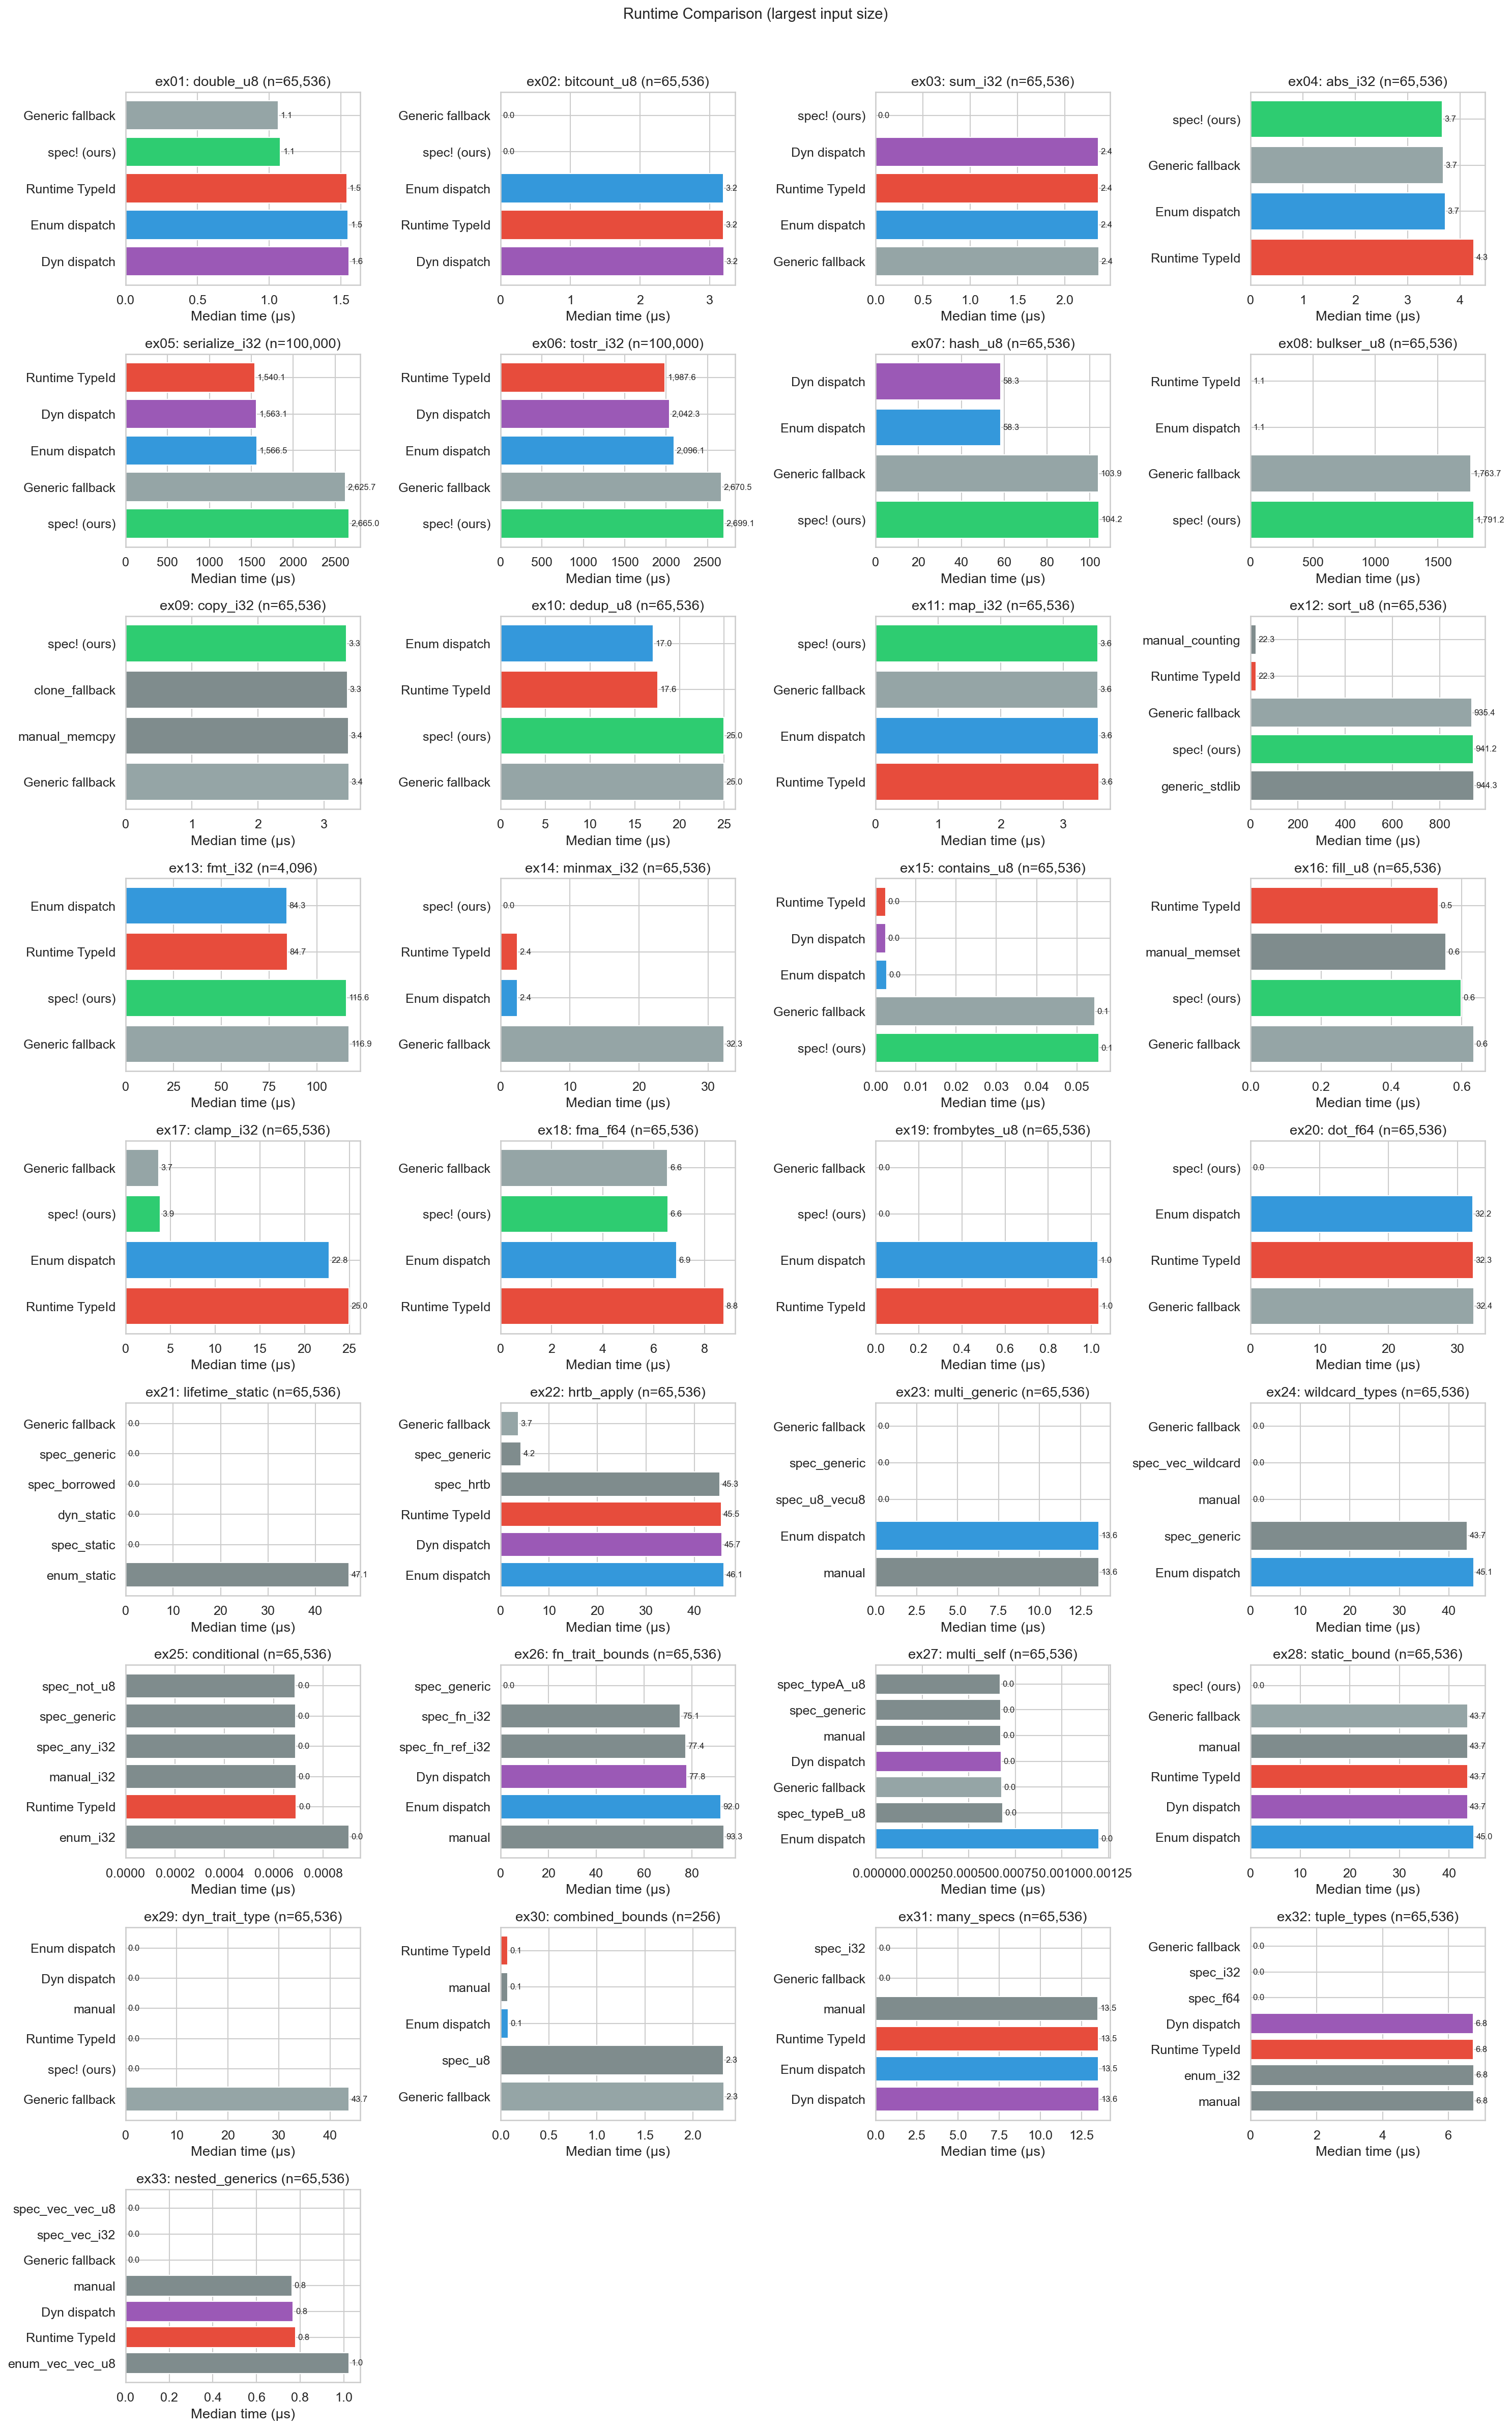

In [3]:
def plot_example_bars(df, example, ax=None):
    """Bar chart for a single example at the largest size."""
    sub = df[df["example"] == example].copy()
    if sub.empty:
        return
    largest = sub["size"].max()
    sub = sub[sub["size"] == largest]
    sub = sub.sort_values("median_ns")
    op = sub["operation"].iloc[0]

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.5))
    colors = [PALETTE.get(lab, "#7f8c8d") for lab in sub["approach_label"]]
    bars = ax.barh(sub["approach_label"], sub["median_us"], color=colors)
    ax.set_xlabel("Median time (µs)")
    ax.set_title(f"{example}: {op} (n={largest:,})")
    ax.invert_yaxis()
    for bar, val in zip(bars, sub["median_us"]):
        ax.text(bar.get_width() + 0.01 * sub["median_us"].max(),
                bar.get_y() + bar.get_height() / 2,
                f"{val:,.1f}", va="center", fontsize=8)
    return ax


if len(df) > 0:
    examples = sorted(df["example"].unique())
    ncols = 4
    nrows = (len(examples) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3.5))
    axes = axes.flatten()
    for i, ex in enumerate(examples):
        plot_example_bars(df, ex, ax=axes[i])
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
    fig.suptitle("Runtime Comparison (largest input size)", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "runtime_bars.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("No data to plot.")

## 3. Runtime — Scaling Curves

Show how each approach scales with input size for selected examples.

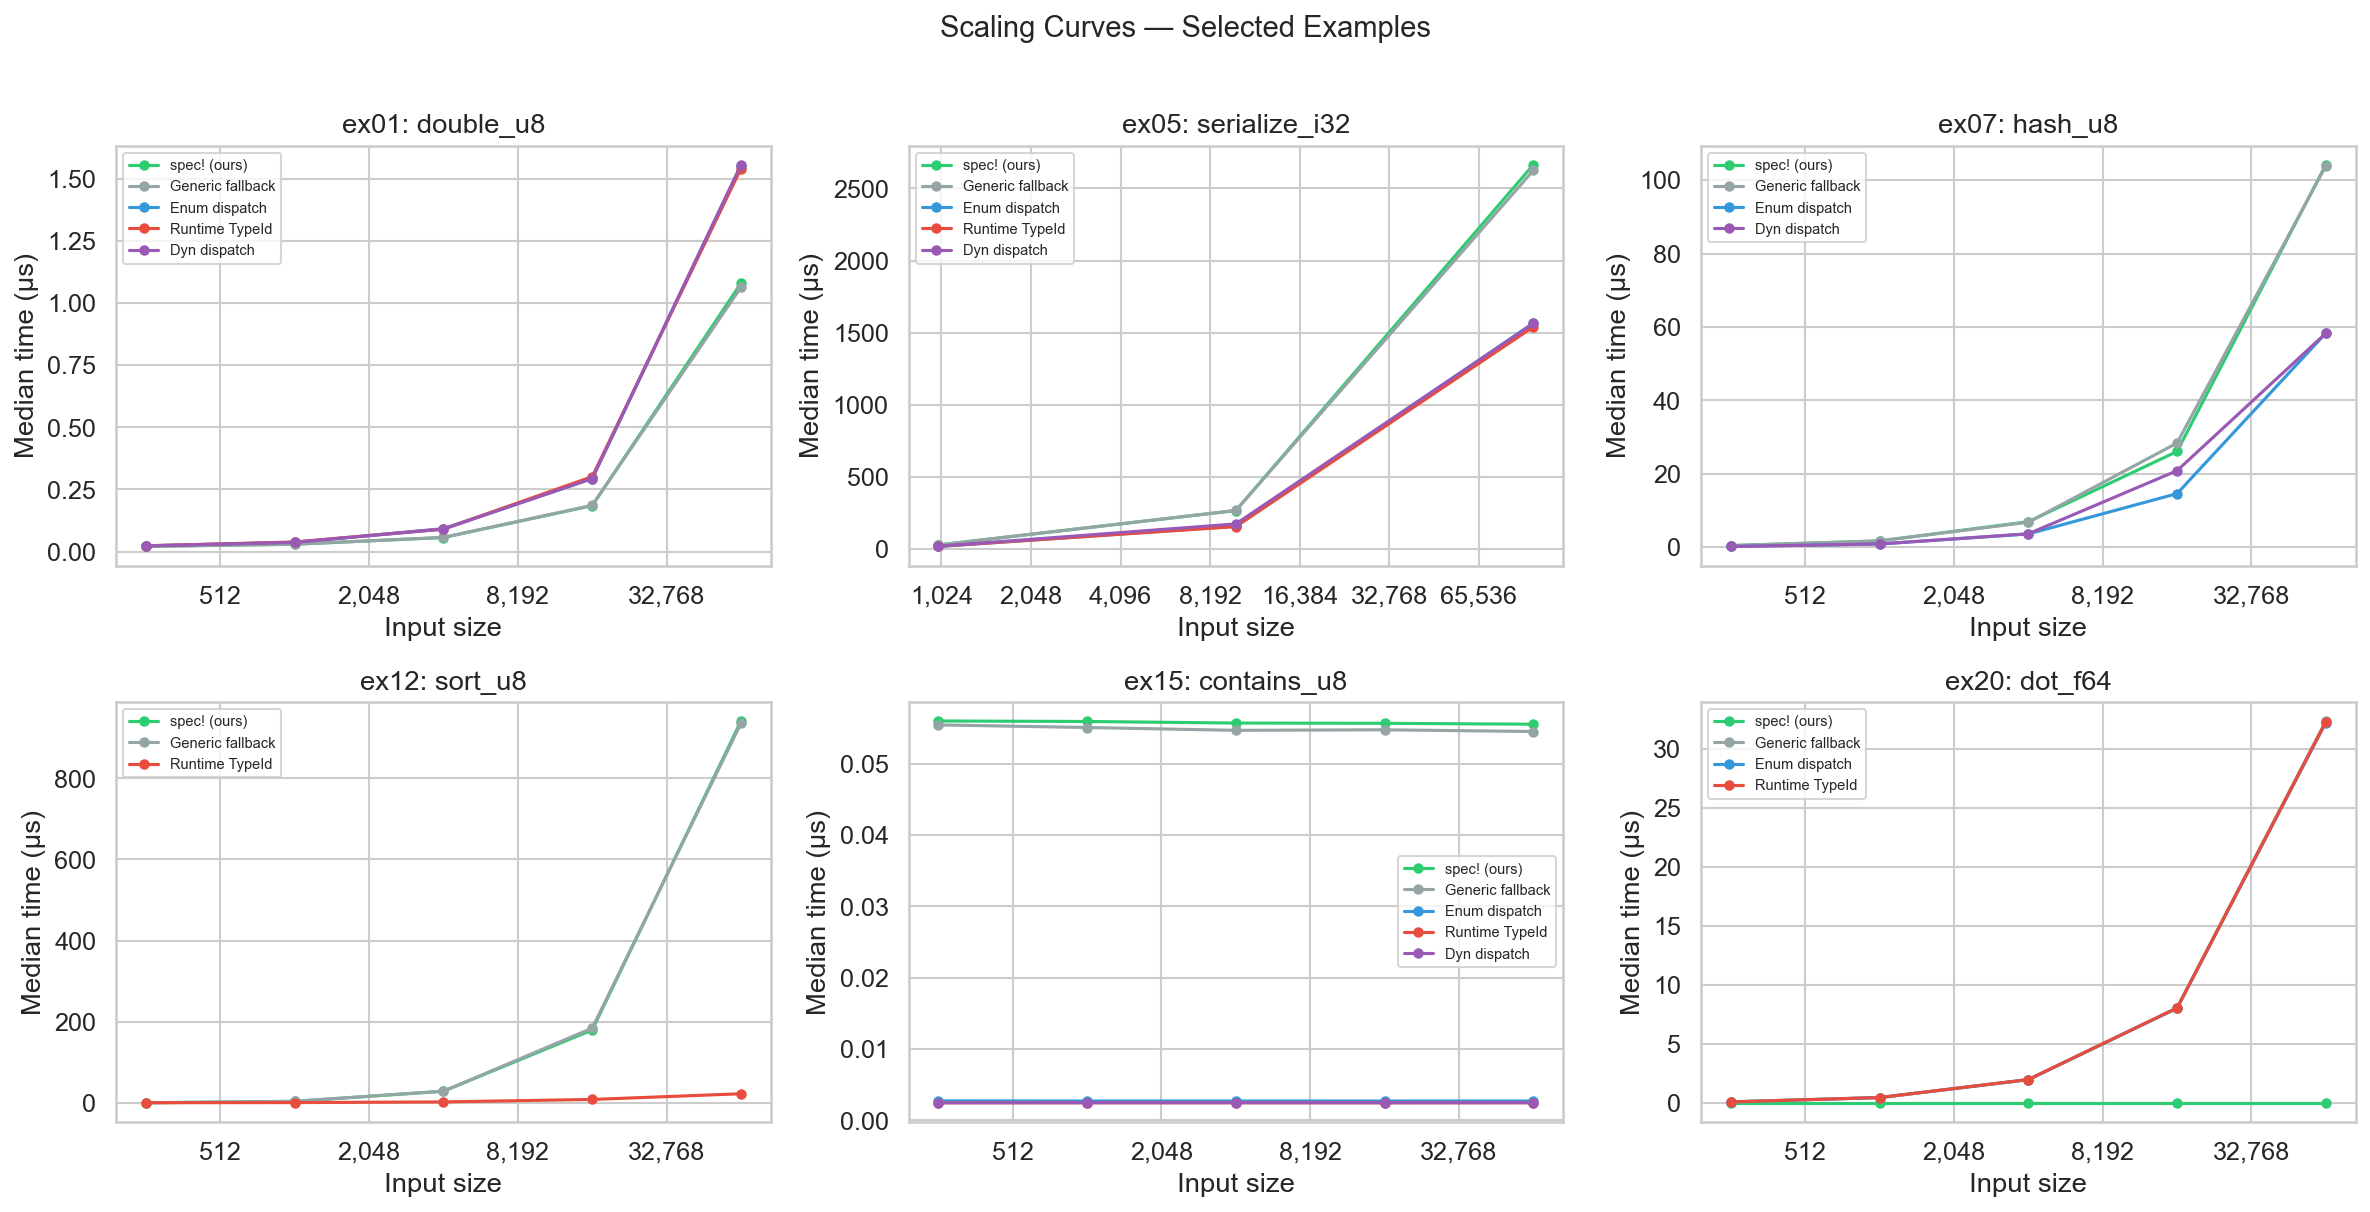

In [4]:
def plot_scaling(df, example, ax=None):
    """Line plot of median time vs input size for one example."""
    sub = df[df["example"] == example].copy()
    if sub.empty or sub["size"].isna().all():
        return
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    for approach in APPROACH_ORDER:
        a = sub[sub["approach"] == approach].sort_values("size")
        if a.empty:
            continue
        label = APPROACH_LABELS.get(approach, approach)
        ax.plot(a["size"], a["median_us"], "o-",
                label=label, color=PALETTE.get(label, None), markersize=4)
    op = sub["operation"].iloc[0]
    ax.set_xlabel("Input size")
    ax.set_ylabel("Median time (µs)")
    ax.set_title(f"{example}: {op}")
    ax.legend(fontsize=7)
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    return ax


if len(df) > 0:
    # Pick 6 representative examples
    highlights = ["ex01", "ex05", "ex07", "ex12", "ex15", "ex20"]
    highlights = [e for e in highlights if e in df["example"].values]
    if not highlights:
        highlights = sorted(df["example"].unique())[:6]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for i, ex in enumerate(highlights):
        plot_scaling(df, ex, ax=axes.flatten()[i])
    for j in range(len(highlights), 6):
        axes.flatten()[j].set_visible(False)
    fig.suptitle("Scaling Curves — Selected Examples", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "scaling_curves.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("No data to plot.")

## 4. Speed-up Summary (spec vs. alternatives)

Compute the speed-up ratio of `spec!` relative to each alternative approach at the largest input size.

vs,Dyn dispatch,Enum dispatch,Generic fallback,Runtime TypeId,clone_fallback,generic_stdlib,manual,manual_counting,manual_memcpy,manual_memset
example,,,,,,,,,,
ex01,1.44,1.44,0.98,1.43,NaN,NaN,NaN,NaN,NaN,NaN
ex02,4492.04,4478.10,0.99,4480.65,NaN,NaN,NaN,NaN,NaN,NaN
ex03,3263.45,3268.38,3275.16,3264.42,NaN,NaN,NaN,NaN,NaN,NaN
ex04,NaN,1.02,1.00,1.17,NaN,NaN,NaN,NaN,NaN,NaN
ex05,0.59,0.59,0.99,0.58,NaN,NaN,NaN,NaN,NaN,NaN
ex06,0.76,0.78,0.99,0.74,NaN,NaN,NaN,NaN,NaN,NaN
ex07,0.56,0.56,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ex08,NaN,0.00,0.98,0.00,NaN,NaN,NaN,NaN,NaN,NaN
ex09,NaN,NaN,1.01,NaN,1.0,NaN,NaN,NaN,1.01,NaN


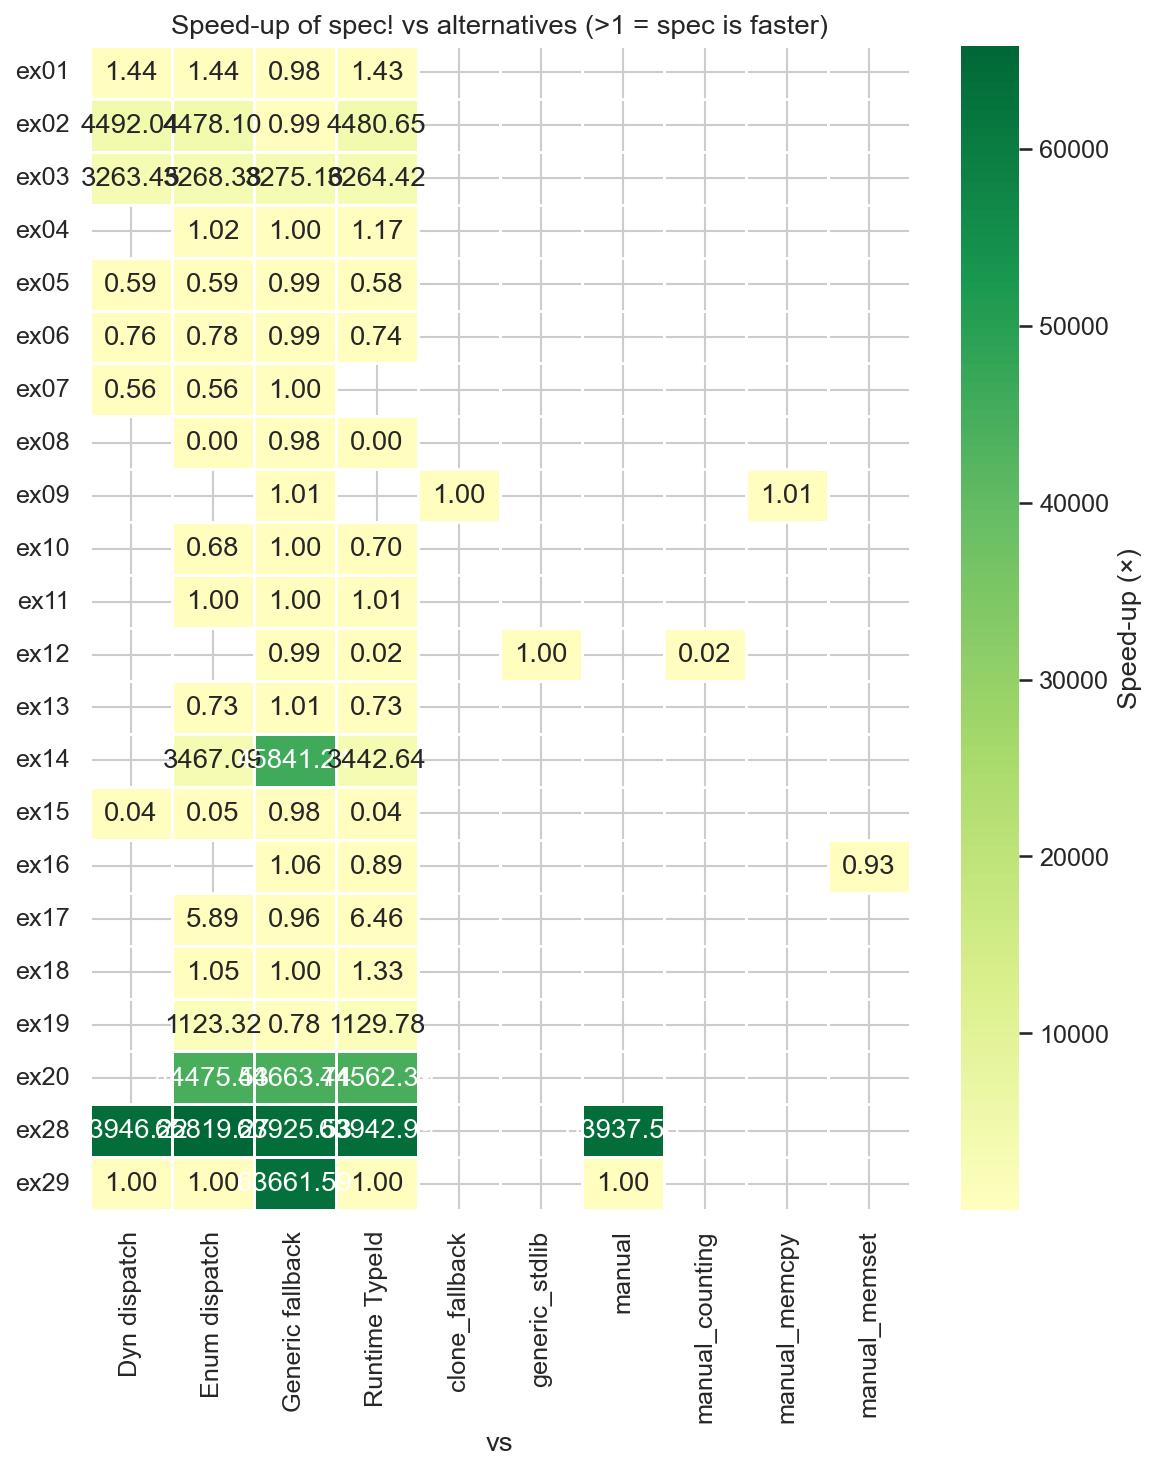

In [5]:
if len(df) > 0:
    # For each example, compute speedup at largest size
    records = []
    for ex in sorted(df["example"].unique()):
        sub = df[df["example"] == ex]
        largest = sub["size"].max()
        sub = sub[sub["size"] == largest]
        spec_row = sub[sub["approach"] == "spec"]
        if spec_row.empty:
            continue
        spec_time = spec_row["median_ns"].values[0]
        for _, row in sub.iterrows():
            if row["approach"] == "spec":
                continue
            speedup = row["median_ns"] / spec_time if spec_time > 0 else np.nan
            records.append(dict(
                example=ex,
                operation=row["operation"],
                vs=APPROACH_LABELS.get(row["approach"], row["approach"]),
                speedup=speedup,
                spec_ns=spec_time,
                alt_ns=row["median_ns"],
            ))
    speedup_df = pd.DataFrame(records)
    display(speedup_df.pivot_table(index="example", columns="vs", values="speedup").round(2))

    # Heatmap
    pivot = speedup_df.pivot_table(index="example", columns="vs", values="speedup")
    fig, ax = plt.subplots(figsize=(8, 10))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", center=1.0,
                linewidths=0.5, ax=ax, cbar_kws={"label": "Speed-up (×)"})
    ax.set_title("Speed-up of spec! vs alternatives (>1 = spec is faster)")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "speedup_heatmap.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("No data to plot.")

## 5. Throughput Analysis

Elements processed per second at the largest input size.

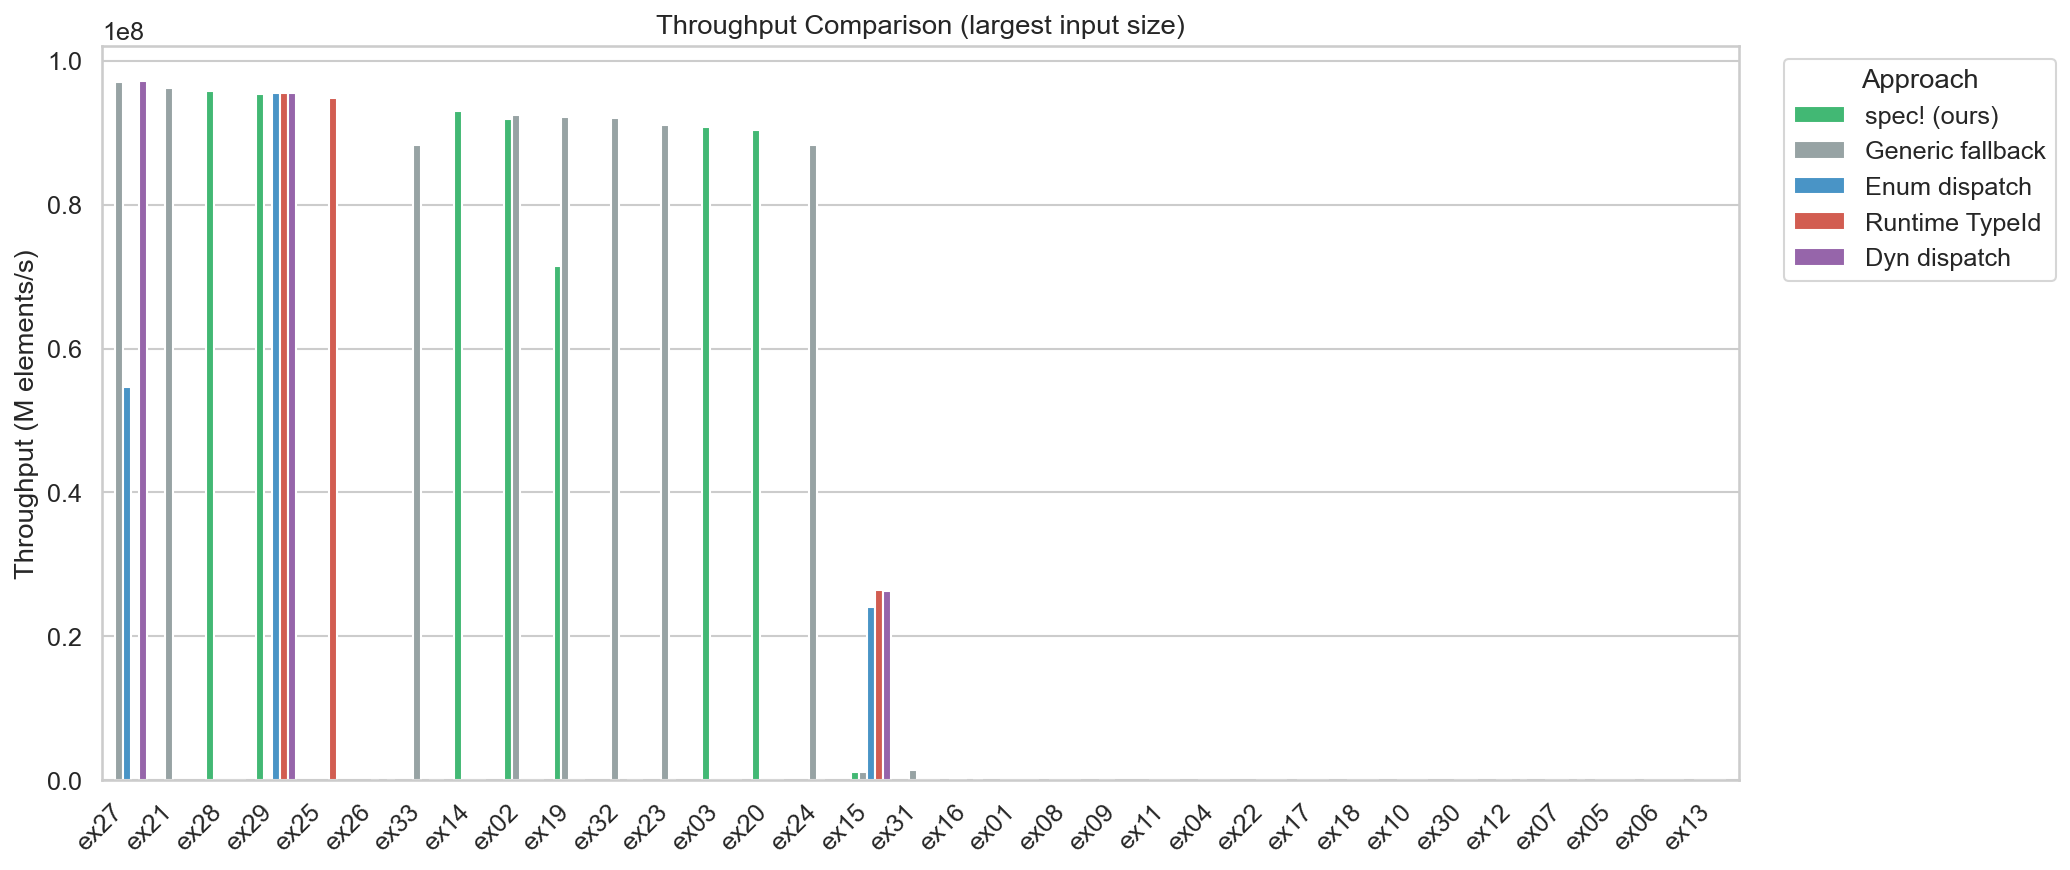

In [6]:
if len(df) > 0:
    largest = df.groupby("example")["size"].transform("max")
    big = df[df["size"] == largest].copy()
    big["throughput_Meps"] = big["size"] / (big["median_ns"] / 1e3)  # M elements/s

    fig, ax = plt.subplots(figsize=(14, 6))
    order = big.groupby("example")["throughput_Meps"].max().sort_values(ascending=False).index
    sns.barplot(data=big, x="example", y="throughput_Meps",
                hue="approach_label", hue_order=[APPROACH_LABELS[a] for a in APPROACH_ORDER if a in big["approach"].values],
                order=order, palette=PALETTE, ax=ax)
    ax.set_ylabel("Throughput (M elements/s)")
    ax.set_xlabel("")
    ax.set_title("Throughput Comparison (largest input size)")
    ax.legend(title="Approach", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "throughput.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("No data to plot.")

## 6. Build Time

Compare compilation time with and without the macro system.

Loaded 147 build-time rows.


ValueError: The palette dictionary is missing keys: {'delta_with_minus_without'}

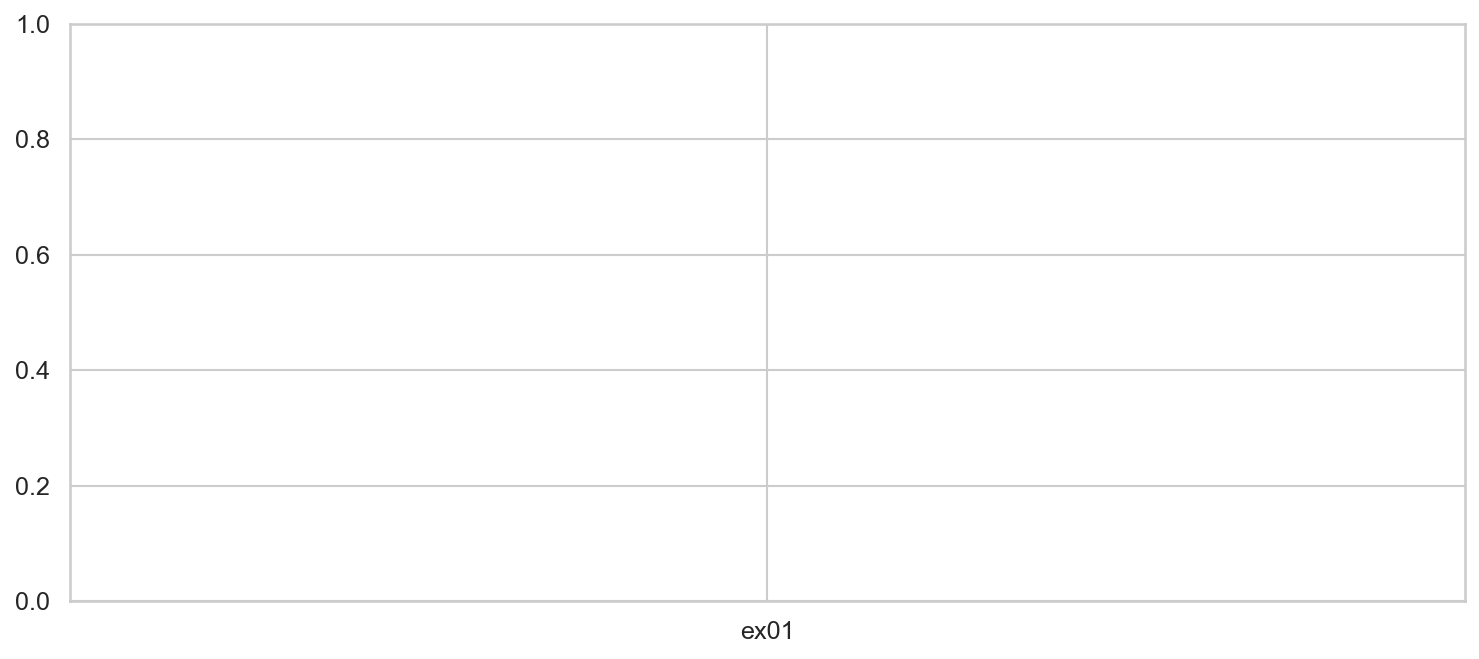

In [7]:
build_csv = RESULTS_DIR / "build_time.csv"
if build_csv.exists():
    bdf = pd.read_csv(build_csv)
    print(f"Loaded {len(bdf)} build-time rows.")

    avg = bdf.groupby(["example", "variant"])["build_time_secs"].agg(["mean", "std"]).reset_index()
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.barplot(data=avg, x="example", y="mean", hue="variant", ax=ax,
                palette={"with_macro": "#2ecc71", "without_macro": "#e74c3c"})
    ax.set_ylabel("Build time (s)")
    ax.set_title("Build Time: With Macros vs Without")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "build_time.pdf"), bbox_inches="tight")
    plt.show()
else:
    print(f"No build time data at {build_csv}. Run: bash ../scripts/measure_build_time.sh")

## 7. Binary Size

Compare release binary sizes.

In [ ]:
bin_csv = RESULTS_DIR / "binary_size.csv"
if bin_csv.exists():
    bsdf = pd.read_csv(bin_csv)
    print(f"Loaded {len(bsdf)} binary-size rows.")
    display(bsdf)

    fig, ax = plt.subplots(figsize=(8, 4))
    bsdf["KB"] = bsdf["binary_size_bytes"] / 1024
    bsdf["stripped_KB"] = bsdf["stripped_size_bytes"] / 1024
    x = range(len(bsdf))
    ax.bar(x, bsdf["KB"], label="Full", color="#3498db", alpha=0.8)
    ax.bar(x, bsdf["stripped_KB"], label="Stripped", color="#2ecc71", alpha=0.8)
    ax.set_xticks(list(x))
    ax.set_xticklabels(bsdf["example"] + " (" + bsdf["variant"] + ")", rotation=45, ha="right")
    ax.set_ylabel("Size (KB)")
    ax.set_title("Binary Size")
    ax.legend()
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "binary_size.pdf"), bbox_inches="tight")
    plt.show()
else:
    print(f"No binary size data at {bin_csv}. Run: bash ../scripts/measure_binary_size.sh")

## 8. Maintainability — Lines of Code

Compare the number of logical lines in each `exNN.rs` (with macros) vs `exNN_wo.rs` (without).

,example,with_macro,without_macro,ratio
0,ex01,34,67,1.97
1,ex02,44,58,1.32
2,ex03,45,60,1.33
3,ex04,41,47,1.15
4,ex05,48,68,1.42
5,ex06,51,52,1.02
6,ex07,53,51,0.96
7,ex08,48,54,1.12
8,ex09,35,71,2.03
9,ex10,56,50,0.89


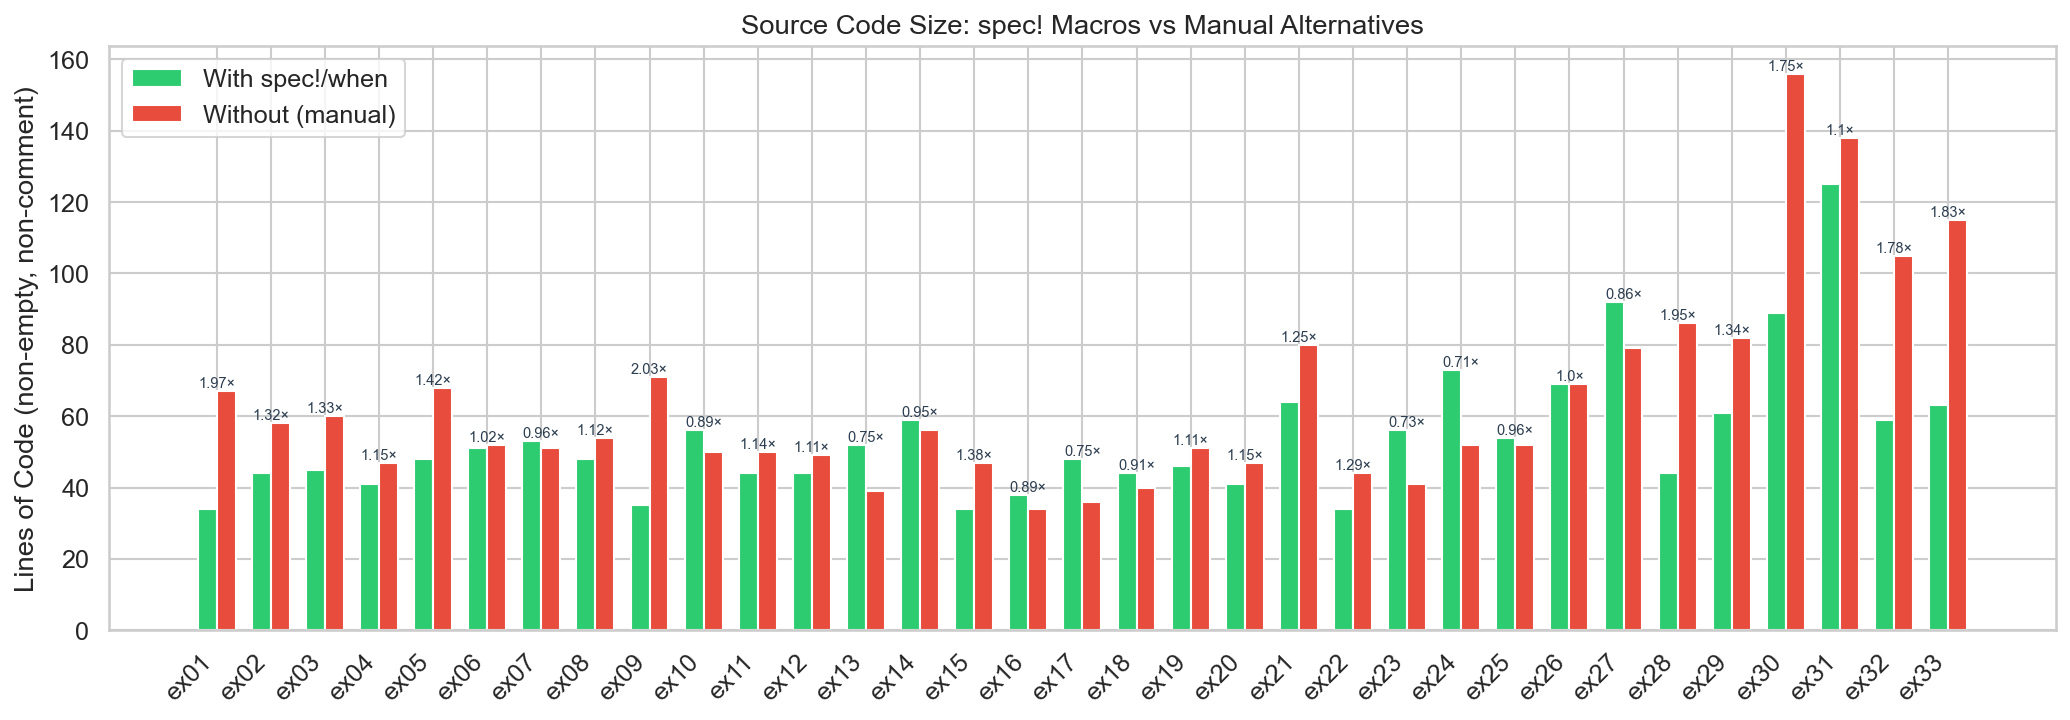


Average ratio without/with: 1.21×
Median ratio: 1.12×


In [8]:
def count_loc(path: Path) -> int:
    """Count non-empty, non-comment lines."""
    count = 0
    for line in path.read_text().splitlines():
        stripped = line.strip()
        if stripped and not stripped.startswith("//"):
            count += 1
    return count

loc_rows = []
for i in range(1, 34):
    name = f"ex{i:02d}"
    with_path = SRC_DIR / f"{name}.rs"
    wo_path = SRC_DIR / f"{name}_wo.rs"
    if with_path.exists() and wo_path.exists():
        loc_rows.append(dict(example=name, with_macro=count_loc(with_path), without_macro=count_loc(wo_path)))

loc_df = pd.DataFrame(loc_rows)
loc_df["ratio"] = (loc_df["without_macro"] / loc_df["with_macro"]).round(2)
display(loc_df)

fig, ax = plt.subplots(figsize=(14, 5))
x = range(len(loc_df))
w = 0.35
ax.bar([xi - w/2 for xi in x], loc_df["with_macro"], w, label="With spec!/when", color="#2ecc71")
ax.bar([xi + w/2 for xi in x], loc_df["without_macro"], w, label="Without (manual)", color="#e74c3c")
ax.set_xticks(list(x))
ax.set_xticklabels(loc_df["example"], rotation=45, ha="right")
ax.set_ylabel("Lines of Code (non-empty, non-comment)")
ax.set_title("Source Code Size: spec! Macros vs Manual Alternatives")
ax.legend()
# Annotate ratio
for xi, ratio in zip(x, loc_df["ratio"]):
    ax.text(xi, max(loc_df["with_macro"].iloc[xi], loc_df["without_macro"].iloc[xi]) + 1,
            f"{ratio}×", ha="center", fontsize=7, color="#2c3e50")
plt.tight_layout()
plt.savefig(str(RESULTS_DIR / "loc_comparison.pdf"), bbox_inches="tight")
plt.show()

print(f"\nAverage ratio without/with: {loc_df['ratio'].mean():.2f}×")
print(f"Median ratio: {loc_df['ratio'].median():.2f}×")

## 9. Statistical Summary Table

A paper-ready LaTeX table of per-example median runtimes and speed-ups.

In [9]:
if len(df) > 0:
    # Build summary table at largest size
    summary_rows = []
    for ex in sorted(df["example"].unique()):
        sub = df[df["example"] == ex]
        largest = sub["size"].max()
        sub = sub[sub["size"] == largest]
        spec_row = sub[sub["approach"] == "spec"]
        if spec_row.empty:
            continue
        spec_us = spec_row["median_us"].values[0]
        row = {"Example": ex, "Operation": sub["operation"].iloc[0],
               "n": int(largest), "spec (µs)": round(spec_us, 2)}
        for appr in ["generic", "enum", "runtime_typeid", "dyn"]:
            alt = sub[sub["approach"] == appr]
            if not alt.empty:
                alt_us = alt["median_us"].values[0]
                row[f"{appr} (µs)"] = round(alt_us, 2)
                row[f"vs {appr}"] = f"{alt_us / spec_us:.2f}×" if spec_us > 0 else "—"
            else:
                row[f"{appr} (µs)"] = "—"
                row[f"vs {appr}"] = "—"
        summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows)
    display(summary_df)

    # Export to LaTeX
    latex_path = RESULTS_DIR / "summary_table.tex"
    summary_df.to_latex(latex_path, index=False, escape=False)
    print(f"LaTeX table saved to {latex_path}")
else:
    print("No data available.")

,Example,Operation,n,spec (µs),generic (µs),vs generic,enum (µs),vs enum,runtime_typeid (µs),vs runtime_typeid,dyn (µs),vs dyn
0,ex01,double_u8,65536,1.08,1.06,0.98×,1.55,1.44×,1.54,1.43×,1.56,1.44×
1,ex02,bitcount_u8,65536,0.00,0.00,0.99×,3.19,4478.10×,3.19,4480.65×,3.2,4492.04×
2,ex03,sum_i32,65536,0.00,2.36,3275.16×,2.36,3268.38×,2.36,3264.42×,2.36,3263.45×
3,ex04,abs_i32,65536,3.66,3.68,1.00×,3.73,1.02×,4.27,1.17×,—,—
4,ex05,serialize_i32,100000,2664.98,2625.70,0.99×,1566.49,0.59×,1540.14,0.58×,1563.11,0.59×
5,ex06,tostr_i32,100000,2699.10,2670.51,0.99×,2096.06,0.78×,1987.56,0.74×,2042.26,0.76×
6,ex07,hash_u8,65536,104.21,103.88,1.00×,58.32,0.56×,—,—,58.29,0.56×
7,ex08,bulkser_u8,65536,1791.18,1763.74,0.98×,1.1,0.00×,1.1,0.00×,—,—
8,ex09,copy_i32,65536,3.33,3.37,1.01×,—,—,—,—,—,—
9,ex10,dedup_u8,65536,24.97,24.98,1.00×,17.04,0.68×,17.55,0.70×,—,—


ImportError: `Import Jinja2` failed. DataFrame.style requires jinja2. Use pip or conda to install the Jinja2 package.

## 10. Violin Plot — Overall Distribution

Show the distribution of speed-ups across all 33 examples.

In [ ]:
if len(df) > 0 and len(speedup_df) > 0:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.violinplot(data=speedup_df, x="vs", y="speedup", inner="box",
                   palette="Set2", ax=ax, cut=0)
    ax.axhline(1.0, color="gray", linestyle="--", alpha=0.7, label="parity")
    ax.set_ylabel("Speed-up factor (spec! time / alt time)")
    ax.set_xlabel("")
    ax.set_title(\"Distribution of Speed-ups Across 33 Examples\")
    plt.tight_layout()
    plt.savefig(str(RESULTS_DIR / "speedup_violin.pdf"), bbox_inches="tight")
    plt.show()

    print("\nPer-alternative summary:")
    display(speedup_df.groupby("vs")["speedup"].describe().round(2))
else:
    print("No data to plot.")

## 11. Export All Figures

Verify that all PDFs for the paper are generated.

In [ ]:
expected_figs = [
    "runtime_bars.pdf", "scaling_curves.pdf", "speedup_heatmap.pdf",
    "throughput.pdf", "loc_comparison.pdf", "speedup_violin.pdf",
    "summary_table.tex",
]
for name in expected_figs:
    p = RESULTS_DIR / name
    status = "OK" if p.exists() else "MISSING"
    size = f"({p.stat().st_size / 1024:.1f} KB)" if p.exists() else ""
    print(f"  [{status}] {name} {size}")

print("\nAll paper-ready figures exported to", RESULTS_DIR.resolve())